# 02 - Clean, split and analyse

All cleaning lives in `src/clean.py::build_dataset()` and rebuilds the data from the raw files. This notebook shows the audit, the split and the analysis required for Part C. **Exploration uses May (training) only**, except the month-to-month stability check, which uses only the label rate.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from src.clean import *
from src.features import *
from src.models import *
from src.evaluate import *
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
df, audit = build_dataset()
train, val, test = [df[df.split == s].reset_index(drop=True) for s in ("train", "validation", "test")]


## 0. Grain: what one row stands for, and joins that cannot multiply rows
A table's *grain* is what one row stands for. We test it instead of assuming it, and every join goes through `join_checked`, which stops if the row count changes.

In [2]:
trips_raw, zones_raw = load_raw()
grain = pd.DataFrame([
    {"table": "trips", "one row is": "one yellow-taxi trip (there is no ID column)", "key tested": "all 21 columns together", "holds?": is_key(trips_raw, list(trips_raw.columns))},
    {"table": "zones", "one row is": "one taxi zone", "key tested": "LocationID", "holds?": is_key(zones_raw, ["LocationID"])},
])
print(grain.to_string(index=False))
merged = add_zone_names(trips_raw, zones_raw)       # two checked joins (pickup zone, drop-off zone)
print(f"rows before the zone joins: {len(trips_raw):,}  after both joins: {len(merged):,}")
assert trips_raw.PULocationID.isin(zones_raw.LocationID).all() and trips_raw.DOLocationID.isin(zones_raw.LocationID).all()
print("every pickup and drop-off zone exists in the lookup")
zones_raw[zones_raw.duplicated("Zone", keep=False)][["LocationID", "Borough", "Zone"]]

table                                   one row is              key tested  holds?
trips one yellow-taxi trip (there is no ID column) all 21 columns together    True
zones                                one taxi zone              LocationID    True
rows before the zone joins: 600,000  after both joins: 600,000
every pickup and drop-off zone exists in the lookup


,LocationID,Borough,Zone
55,56,Queens,Corona
56,57,Queens,Corona
102,103,Manhattan,Governor's Island/Ellis Island/Liberty Island
103,104,Manhattan,Governor's Island/Ellis Island/Liberty Island
104,105,Manhattan,Governor's Island/Ellis Island/Liberty Island


**Reading it.** Both keys hold, and the join keeps exactly 600,000 rows. Five zone IDs share names (56 and 57 are both 'Corona'; 103, 104, 105 are all 'Governor's Island/Ellis Island/Liberty Island'). That is harmless, because we join on the ID, never on the name. There is one trips table and one lookup, so the grain problem of many-to-many joins does not arise, but we still test it.

## 1. Audit and decisions (findings table)
Each rule removes the rows it names (counted in order, so the removals add up). `positive_rate_of_removed` is the crawl share among removed rows where a speed exists. Rows kept but flagged are listed at the bottom.

In [3]:
a = audit.copy(); a['positive_rate_of_removed'] = a.positive_rate_of_removed.round(3)
print(f'raw rows: 600,000 -> clean rows: {len(df):,}  ({100*len(df)/600000:.1f}% kept)')
a

raw rows: 600,000 -> clean rows: 559,203  (93.2% kept)


,problem,decision,rows_removed,positive_rate_of_removed,rows_affected,share_of_raw_%
0,pickup outside May-July 2026,drop,2,0.000,NaN,0.00
1,duration <= 0 (drop-off not after pickup),drop,7676,NaN,NaN,1.28
2,duration < 1 min,drop,6407,0.792,NaN,1.07
3,duration > 180 min,drop,180,0.939,NaN,0.03
4,distance < 0.1 mi (incl. zero),drop,18081,1.000,NaN,3.01
5,negative or zero fare / total amount,drop,2071,0.218,NaN,0.35
6,"unknown pickup or drop-off zone (264, 265)",drop,3747,0.054,NaN,0.62
7,payment type 3 (no charge) or 4 (dispute) or 6...,drop,2531,0.274,NaN,0.42
8,speed > 80 mph,drop,102,0.000,NaN,0.02
9,flex fare trips (payment type 0),keep + flag,0,0.098,137143.0,0.00


| Problem | Decision and defence |
|---|---|
| Pickup outside May-July | 2 April rows; outside the split, drop |
| Duration <= 0, < 1 min, > 3 h | speed undefined or noise; drop (these are 79-94% 'crawls' when defined, which would pollute the label) |
| Distance < 0.1 mi / zero | cannot compute a meaningful speed; every one would be a fake crawl; drop |
| Negative / zero fare or total | refunds, corrections, not real trips; drop |
| Unknown zones 264/265 | no zone to learn from or map; drop (0.6%) |
| Payment type 3 / 4 / 6 | no charge, dispute, voided: not completed ordinary fares; drop (0.4%). Type 6 does not occur in the sample |
| Speed > 80 mph | impossible; drop (102 rows) |
| **Flex fare (type 0)** | **kept** and flagged (`is_flex`). They are a quarter of trips and real, measured trips; the target needs only distance and duration, which they have. They have no passenger count or rate code, but we use neither. Dropping them would change the population the dispatcher serves |
| Non-standard rate codes (2-6, 99) | **kept**; real trips (JFK flat fare, negotiated...). The rate code is set at the trip end so is not used as a feature |
| Airport trips | kept; analysed separately below |

### The six-category checklist (counts on the raw data, each with a decision and a reason)
The ordered audit above counts each row once. This table lists every problem by category, so each of the six checks is visibly done.

In [4]:
r2 = add_target_pieces(trips_raw); miss = trips_raw.isna().sum(); n_flex = int((trips_raw.payment_type == 0).sum())
months_ok = trips_raw.tpep_pickup_datetime.dt.month.isin([5, 6, 7]) & (trips_raw.tpep_pickup_datetime.dt.year == 2026)
rows = [
 ("Missing", f"{int(miss['passenger_count']):,} trips lack passenger count, rate code, store flag, congestion and airport fee; exactly the {n_flex:,} flex-fare trips", "Flag (is_flex)", "None of those columns is a feature; the target only needs distance and duration"),
 ("Missing", f"request_source is empty for {int(miss['request_source']):,} trips", "Flag", "Unknown meaning, never used"),
 ("Missing", "zone 264 has borough 'N/A' (read as missing) and zone 265 'Unknown'", "Drop their trips", "No zone to learn from or map"),
 ("Impossible", f"{int((r2.duration_min <= 0).sum()):,} trips where drop-off is not after pickup", "Drop", "Speed is undefined"),
 ("Impossible", f"{int(((r2.duration_min > 0) & (r2.speed_mph > 80)).sum()):,} trips above 80 mph among trips with a positive duration (raw count)", "Drop", "Not possible inside New York"),
 ("Out of range", f"{int((trips_raw.trip_distance < 0.1).sum()):,} trips under 0.1 mile (incl. zero)", "Drop", "Distance is not meaningful and would fake a crawl"),
 ("Out of range", f"{int((r2.duration_min > 180).sum()):,} trips over 3 hours; {int((r2.duration_min.between(0, 1, inclusive='neither')).sum()):,} under 1 minute (raw counts)", "Drop", "Meter left running / rounding noise"),
 ("Out of range", f"{int((~months_ok).sum()):,} trips picked up outside May-July 2026", "Drop", "Outside the split"),
 ("Out of range", f"{int(((trips_raw.fare_amount <= 0) | (trips_raw.total_amount <= 0)).sum()):,} trips with zero or negative fare or total", "Drop", "Refunds or corrections, not ordinary trips"),
 ("Inconsistent", f"{int(trips_raw.payment_type.isin([3, 4]).sum()):,} no-charge or disputed trips (payment 3, 4)", "Drop", "Not ordinary paid trips; their crawl rate looks abnormal"),
 ("Inconsistent", f"{int(trips_raw.RatecodeID.isin([2, 3, 4, 5, 6, 99]).sum()):,} trips with a non-standard rate code", "Keep + flag", "Real trips; the code is only set at the end so it is not a feature"),
 ("Duplicated", f"{int(trips_raw.duplicated().sum())} exact duplicate trips", "None needed", "Tested with duplicated()"),
 ("Duplicated", "5 zone IDs share 2 names (see above)", "None needed", "We join on the ID, not the name"),
 ("Misnamed", "column 'Airport_fee' is capitalised unlike the others", "Fix", "Renamed to airport_fee in clean(); it is not used as a feature anyway"),
]
pd.DataFrame(rows, columns=["category", "finding", "decision", "reason"])

,category,finding,decision,reason
0,Missing,"154,475 trips lack passenger count, rate code,...",Flag (is_flex),None of those columns is a feature; the target...
1,Missing,"request_source is empty for 492,156 trips",Flag,"Unknown meaning, never used"
2,Missing,zone 264 has borough 'N/A' (read as missing) a...,Drop their trips,No zone to learn from or map
3,Impossible,"7,676 trips where drop-off is not after pickup",Drop,Speed is undefined
4,Impossible,158 trips above 80 mph among trips with a posi...,Drop,Not possible inside New York
5,Out of range,"24,209 trips under 0.1 mile (incl. zero)",Drop,Distance is not meaningful and would fake a crawl
6,Out of range,"180 trips over 3 hours; 6,407 under 1 minute (...",Drop,Meter left running / rounding noise
7,Out of range,2 trips picked up outside May-July 2026,Drop,Outside the split
8,Out of range,"2,672 trips with zero or negative fare or total",Drop,"Refunds or corrections, not ordinary trips"
9,Inconsistent,"5,169 no-charge or disputed trips (payment 3, 4)",Drop,Not ordinary paid trips; their crawl rate look...


### Cleaning fixes facts; it never learns
| Step | Fact or learned? |
|---|---|
| Drop duration <= 0, < 1 min, > 3 h, distance < 0.1 mi, speed > 80 mph | **Fact**: fixed physical limits, the same answer on any sample. (We chose the limits after looking at the whole file, but they rest on physics, not on the labels.) |
| Drop negative fares, unknown zones 264/265, payment types 3 and 4 | **Fact**: a property of each row |
| Rename `Airport_fee`, join zone names | **Fact** |
| Fill missing passenger count or rate code with a typical value | **Not done**: that would be learning, and we do not use those columns |
| Planned-distance estimate, zone and zone-pair crawl rates | **Learned**: they live in `ZoneHistory` (`src/features.py`), fitted on May only after the split, out-of-fold inside May |

## 2. The split (by pickup month)

In [5]:
df.groupby('split').agg(trips=('crawl','size'), positive_rate=('crawl','mean')).loc[['train','validation','test']].round(4)

,trips,positive_rate
split,,
train,187612,0.1934
validation,186114,0.1854
test,185477,0.1632


### Why a time split
**Who or when will the model be used on?** On *future* trips in the same city by the same taxi fleet, with zones and zone pairs it has already seen. So the split is **by time** (May train, June validation, July test), as the course sets it. A grouped split (new people or new shops) does not apply: the data has no driver or passenger ID, and zone pairs repeat by design. Zones and pairs that appear in July but not in May fall back to broader averages in `ZoneHistory`.

**Disclosure on exploring the target.** The audit, the cleaning and the structural checks run on all rows and never look at the label. Exploration of the label starts below and uses **May only**, with two exceptions that we state openly: the month-to-month stability check (it needs all three months but looks only at the label rate, and no modelling choice depends on it), and the target ladder in notebook 01, which now uses May only. While we were first developing the project, the label pattern was also looked at on all months, so the feature ideas are re-derived from the May charts below (see the table at the end).

## 3. Positive rate overall, by hour and day of week (May)

May positive rate: 19.343%


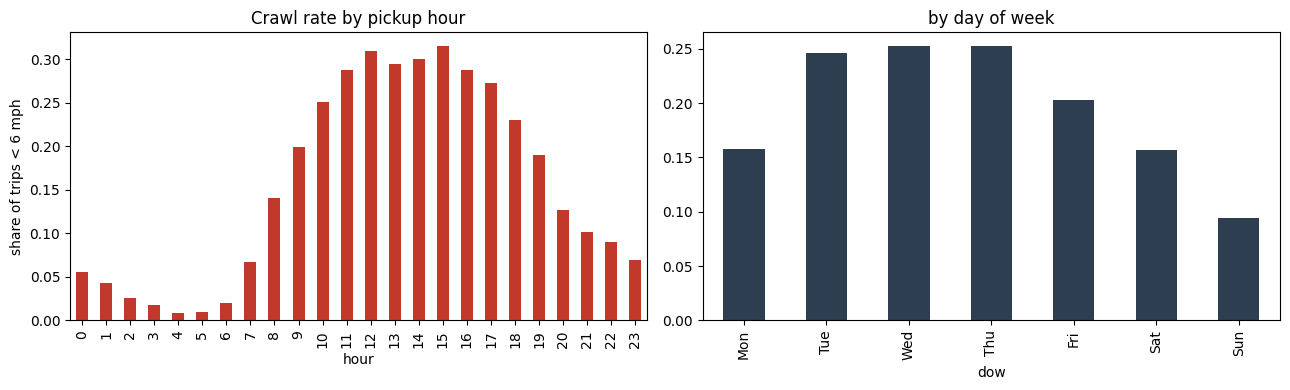

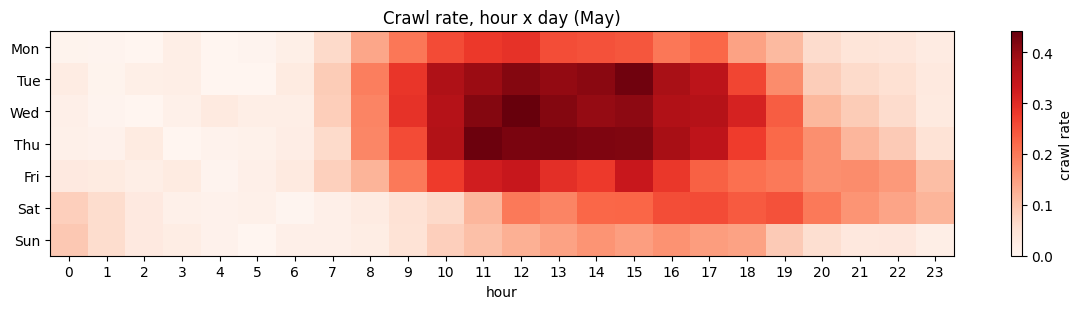

In [6]:
train['hour'] = train.tpep_pickup_datetime.dt.hour; train['dow'] = train.tpep_pickup_datetime.dt.dayofweek
print(f"May positive rate: {train.crawl.mean():.3%}")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
train.groupby('hour').crawl.mean().plot(kind='bar', ax=ax[0], color='#c0392b'); ax[0].set_title('Crawl rate by pickup hour'); ax[0].set_ylabel('share of trips < 6 mph')
train.groupby('dow').crawl.mean().rename(dict(enumerate(['Mon','Tue','Wed','Thu','Fri','Sat','Sun']))).plot(kind='bar', ax=ax[1], color='#2c3e50'); ax[1].set_title('by day of week')
plt.tight_layout(); plt.savefig(FIG/'rate_by_hour_dow.png', dpi=130); plt.show()
heat = train.pivot_table(index='dow', columns='hour', values='crawl', aggfunc='mean')
plt.figure(figsize=(12, 3.2)); plt.imshow(heat.values, aspect='auto', cmap='Reds'); plt.colorbar(label='crawl rate')
plt.yticks(range(7), ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']); plt.xticks(range(24)); plt.xlabel('hour'); plt.title('Crawl rate, hour x day (May)')
plt.tight_layout(); plt.savefig(FIG/'heat_hour_dow.png', dpi=130); plt.show()

**Four-step rhythm for this chart (team: write steps 1 and 3 yourselves; step 1 *before* you rerun the cell)**
1. What we expected: ______
2. The chart (above)
3. What it shows, in one sentence: ______
4. Feature it suggests: `hour`, `dow`, `is_weekend`, `is_rush`

## 4. Positive rate by pickup zone: the map

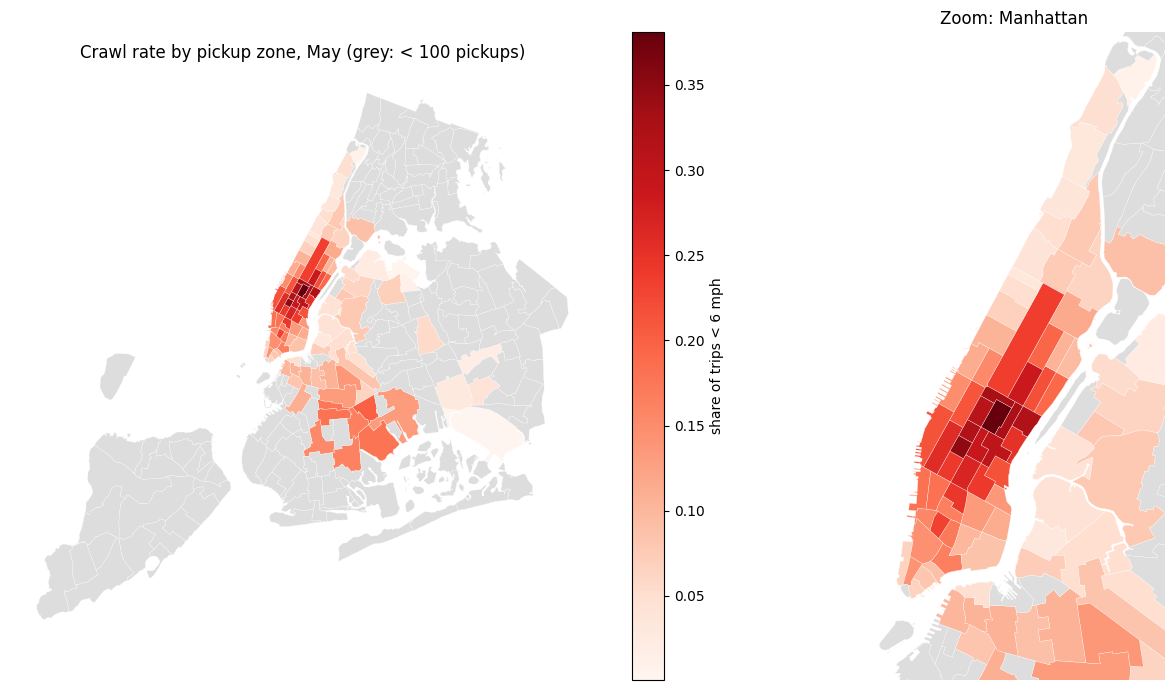

,n,rate,zone,borough
PULocationID,,,,
161,7646,0.381,Midtown Center,Manhattan
186,5306,0.350,Penn Station/Madison Sq West,Manhattan
163,4551,0.328,Midtown North,Manhattan
162,5619,0.326,Midtown East,Manhattan
100,2328,0.317,Garment District,Manhattan
229,3034,0.317,Sutton Place/Turtle Bay North,Manhattan
230,5149,0.307,Times Sq/Theatre District,Manhattan
170,4796,0.303,Murray Hill,Manhattan
164,3441,0.290,Midtown South,Manhattan


In [7]:
import geopandas as gpd
shp = gpd.read_file("../data/raw/taxi_zones/taxi_zones.shp")     # coordinates in feet (EPSG:2263), fine for a map
z = train.groupby('PULocationID').crawl.agg(['size', 'mean']).rename(columns={'size': 'n', 'mean': 'rate'})
m = shp.merge(z, left_on='LocationID', right_index=True, how='left')
m['rate_shown'] = m.rate.where(m.n >= 100)          # grey out zones with < 100 pickups: too noisy
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
m.plot(column='rate_shown', cmap='Reds', legend=True, legend_kwds={'label': 'share of trips < 6 mph'}, missing_kwds={'color': '#dddddd'}, ax=ax[0], edgecolor='white', linewidth=.2)
ax[0].set_title('Crawl rate by pickup zone, May (grey: < 100 pickups)')
m.plot(column='rate_shown', cmap='Reds', missing_kwds={'color': '#dddddd'}, ax=ax[1], edgecolor='white', linewidth=.2)
ax[1].set_xlim(975000, 1010000); ax[1].set_ylim(185000, 260000); ax[1].set_title('Zoom: Manhattan')
for a_ in ax: a_.set_axis_off()
plt.tight_layout(); plt.savefig(FIG/'map_crawl_rate.png', dpi=130); plt.show()
top = z[z.n >= 500].join(shp.set_index('LocationID')[['zone', 'borough']] if 'zone' in shp else shp.set_index('LocationID')[['borough']]).sort_values('rate', ascending=False)
top.head(10).round(3)

**Reading the map.** The darkest zones (about 30-38% crawl) are in Midtown and the east side of Manhattan; the rest of Manhattan is mostly orange-red (15-30%), some Brooklyn zones are moderate (about 10-20%), and Queens, the Bronx and the airports are nearly white. Crawling is a Manhattan-core phenomenon, not a citywide one. Grey zones have fewer than 100 May pickups.

**Four-step rhythm for this chart (team: write steps 1 and 3 yourselves; step 1 *before* you rerun the cell)**
1. What we expected: ______
2. The chart (above)
3. What it shows, in one sentence: ______
4. Feature it suggests: zone crawl rates `pu_rate`, `do_rate`, and the borough flags

## 5. Which trips crawl?

                        size   mean  share_of_all_crawls
route                                                   
across boroughs        28414  0.020                0.015
within Manhattan      151314  0.231                0.962
within other borough    7884  0.105                0.023 

                    size   mean  share_of_all_crawls
airport                                             
airport drop-off    3317  0.005                0.000
airport pickup     11345  0.002                0.001
no airport        172950  0.210                0.999 

            size   mean  share_of_all_crawls
dist_band                                   
<0.5        7860  0.519                0.112
0.5-1      31746  0.359                0.314
1-2        56742  0.255                0.399
2-3        29549  0.148                0.121
3-5        25198  0.064                0.045
5-10       22541  0.014                0.009
>10        13976  0.003                0.001 



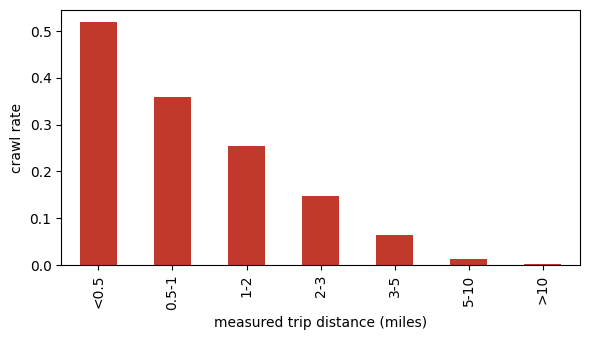

In [8]:
t = train.copy()
t['route'] = np.where(t.pickup_borough != t.dropoff_borough, 'across boroughs', np.where(t.pickup_borough == 'Manhattan', 'within Manhattan', 'within other borough'))
t['airport'] = np.select([t.PULocationID.isin(AIRPORTS), t.DOLocationID.isin(AIRPORTS)], ['airport pickup', 'airport drop-off'], 'no airport')
t['dist_band'] = pd.cut(t.trip_distance, [0, .5, 1, 2, 3, 5, 10, 200], labels=['<0.5', '0.5-1', '1-2', '2-3', '3-5', '5-10', '>10'])
out = {}
for col in ['route', 'airport', 'dist_band']:
    g = t.groupby(col, observed=True).crawl.agg(['size', 'mean']); g['share_of_all_crawls'] = t.groupby(col, observed=True).crawl.sum() / t.crawl.sum()
    out[col] = g.round(3); print(out[col], '\n')
fig, ax = plt.subplots(figsize=(6, 3.5)); out['dist_band']['mean'].plot(kind='bar', ax=ax, color='#c0392b'); ax.set_ylabel('crawl rate'); ax.set_xlabel('measured trip distance (miles)'); plt.tight_layout(); plt.savefig(FIG/'rate_by_distance.png', dpi=130); plt.show()

**Answer.** Crawling trips are overwhelmingly **short (under ~3 miles), within Manhattan**. Trips across boroughs and to or from airports almost never crawl. The measured distance here is only for describing the data; as a feature we may use only the planned distance.

**Four-step rhythm for this chart (team: write steps 1 and 3 yourselves; step 1 *before* you rerun the cell)**
1. What we expected: ______
2. The chart (above)
3. What it shows, in one sentence: ______
4. Feature it suggests: planned distance `est_dist`; `same_borough`, `same_zone` and the airport flags

## 6. Is the positive rate stable from May to June to July?
This uses only the label rate, no model, so July stays unseen for modelling decisions.

month
5    0.1934
6    0.1854
7    0.1632
Name: crawl, dtype: float64


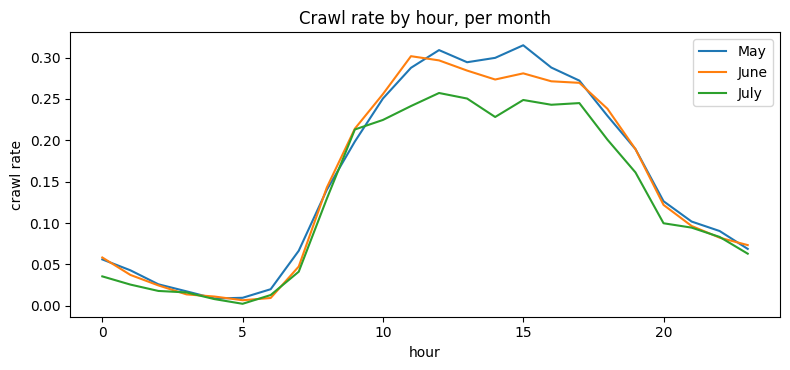

month
5    1.95
6    1.91
7    2.00
Name: median distance, dtype: float64


In [9]:
df['hour'] = df.tpep_pickup_datetime.dt.hour
print(df.groupby('month').crawl.mean().round(4))
fig, ax = plt.subplots(figsize=(8, 3.8))
for mth, g in df.groupby('month'): g.groupby('hour').crawl.mean().plot(ax=ax, label={5: 'May', 6: 'June', 7: 'July'}[mth])
ax.legend(); ax.set_title('Crawl rate by hour, per month'); ax.set_ylabel('crawl rate'); plt.tight_layout(); plt.savefig(FIG/'stability_months.png', dpi=130); plt.show()
print(df.groupby('month').trip_distance.median().round(2).rename('median distance'))

**Answer.** Not perfectly stable: the rate falls from about 19.3% (May) to 18.5% (June) to 16.3% (July). The shape across the day is the same, but July is lower at midday. This is concept drift, so July will be a harder, honest test and the reliability check in notebook 04 matters.

## 7. Random split versus time split (Week 1 baselines, May and June only)
A random split answers 'does this pattern exist in my data?'. A time split answers 'will it still hold next month?'. We score the two Week 1 baselines both ways. July stays untouched, so the random split pools **May and June only**. The no-skill PR AUC equals the positive rate, which differs between periods, so we also report **PR AUC lift = PR AUC / positive rate** (1 = no better than guessing); top-10% lift is shown too.

In [10]:
from sklearn.model_selection import train_test_split
def score_baselines(tr, te):
    M_, _ = build_matrix(tr, {"te": te}); y = te.crawl.values
    rule = BusyRule().fit(tr); t2 = make_tree(2).fit(M_["train"][ALL_FEATS], tr.crawl.values)
    out = {}
    for name, p in [("busy-hours rule", rule.predict_proba(te)[:, 1]), ("depth-2 tree", t2.predict_proba(M_["te"][ALL_FEATS])[:, 1])]:
        m = metrics(y, p, .3); out[name] = {"positive rate": m["base_rate"], "PR AUC": m["pr_auc"], "PR AUC lift": m["pr_auc_lift"], "top-10% lift": m["lift@10%"]}
    return pd.DataFrame(out).T
pool = df[df.month.isin([5, 6])].reset_index(drop=True)
tr_r, te_r = train_test_split(pool, test_size=(pool.month == 6).mean(), random_state=42)
tr_r, te_r = tr_r.reset_index(drop=True), te_r.reset_index(drop=True)
cmp_split = pd.concat({"random split (May+June pooled)": score_baselines(tr_r, te_r), "time split (train May, test June)": score_baselines(train, val)})
cmp_split.round(3)

positive rate  PR AUC  PR AUC lift  top-10% lift
random split (May+June pooled)    busy-hours rule          0.189   0.251        1.327         1.696
                                  depth-2 tree             0.189   0.442        2.336         3.243
time split (train May, test June) busy-hours rule          0.185   0.244        1.315         1.769
                                  depth-2 tree             0.185   0.447        2.411         3.302

**What it shows.** The two blocks are very close (depth-2 tree: PR AUC lift 2.34 random vs 2.41 time). We expected the random split to flatter the baselines, as it did in the lecture's example, but it does not here: May and June look alike, so a simple rule and a shallow tree do not memorise a period. The big shift only shows up in **July** (positive rate 16.3% vs 18.5%), which is why July is scored once at the end and compared by lift, not raw PR AUC. Only the time-split numbers are used for any decision.

## 8. What the charts told us: features suggested
| Chart | What it shows | Feature suggested |
|---|---|---|
| Hour x weekday heatmap | Crawls cluster in weekday daytime and the afternoon rush; nights are almost free | `hour`, `dow`, `is_weekend`, `is_rush` |
| Zone map | Dark in Midtown and the east side of Manhattan, pale at the airports and in Queens | `pu_rate`, `do_rate`, borough flags |
| Distance bands | Short trips crawl far more often than long ones | planned distance `est_dist` (estimated from May) |
| Within or across boroughs, airports | Crawls are almost all within Manhattan; airport trips almost never crawl | `same_borough`, `same_zone`, airport flags |
| Month-to-month rate | 19.3%, 18.5%, 16.3%: the rate drifts | none as a feature; a warning to re-check the threshold and to compare by lift, not raw PR AUC |